# Project Deliverable 2: Regression Modeling and Performance Evaluation

Name: Sandip Sitaula

Course: MSCS 634 - Advanced Big Data and Data Mining

Deliverable 2: Regression Modeling and Performance Evaluation

## Step 1: Goal

In Deliverable 1, I cleaned the Online Retail dataset from the UCI Machine Learning Repository. It has sales from a UK online gift store from December 2010 to December 2011.

In this deliverable, I want to predict how much each customer will spend in the next 3 months, based on how they bought in the past. This is useful for a store because it can plan stock and marketing for its best customers.

I split the data by time so the model only uses information it would really have:

- Past period (features): December 1, 2010 to August 31, 2011 (9 months)
- Future period (target): September 1, 2011 to November 30, 2011 (3 months)

I do not use December 2011, because the data stops on December 9, so it is not a full month.

In [1]:
# Libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, KFold, cross_validate
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

sns.set_theme(style="whitegrid")
pd.set_option("display.float_format", "{:,.3f}".format)

## Step 2: Load the Clean Data

In [2]:
# Load clean data from Deliverable 1
sales = pd.read_csv("data/online_retail_clean.csv.gz", parse_dates=["InvoiceDate"])
cancels = pd.read_csv("data/cancellations.csv.gz", parse_dates=["InvoiceDate"])

# Only rows with a CustomerID
sales = sales[sales["HasCustomerID"]]
cancels = cancels[cancels["HasCustomerID"]]

print("Sales rows:", sales.shape)
print("Cancellation rows:", cancels.shape)
sales.head()

Sales rows: (391129, 12)
Cancellation rows: (8486, 9)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,HasCustomerID,LineTotal,DayOfWeek,Hour
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.550,"17,850.000",United Kingdom,True,15.300,Wednesday,8
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.390,"17,850.000",United Kingdom,True,20.340,Wednesday,8
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.750,"17,850.000",United Kingdom,True,22.000,Wednesday,8
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.390,"17,850.000",United Kingdom,True,20.340,Wednesday,8
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.390,"17,850.000",United Kingdom,True,20.340,Wednesday,8


I use the clean data saved in Deliverable 1. I only keep rows with a CustomerID, because I am predicting spending for each customer.

In [3]:
# Split by time
cutoff = pd.Timestamp("2011-09-01")
target_end = pd.Timestamp("2011-12-01")

past = sales[sales["InvoiceDate"] < cutoff]
future = sales[(sales["InvoiceDate"] >= cutoff) & (sales["InvoiceDate"] < target_end)]
past_cancels = cancels[cancels["InvoiceDate"] < cutoff]

print("Past period:", past["InvoiceDate"].min().date(), "to", past["InvoiceDate"].max().date())
print("Future period:", future["InvoiceDate"].min().date(), "to", future["InvoiceDate"].max().date())
print("Customers in past period:", past["CustomerID"].nunique())

Past period: 2010-12-01 to 2011-08-31
Future period: 2011-09-01 to 2011-11-30
Customers in past period: 3313


3,313 customers bought something in the past period. These are the customers I will make predictions for.

## Step 3: Basic Features and Target

First I make the basic customer features from Deliverable 1 (Recency, Frequency, Monetary, Products, TenureDays), but only using the past period. I also add IsUK (1 if the customer is in the UK).

In [4]:
# Basic customer features from the past period
customers = past.groupby("CustomerID").agg(
    LastOrder=("InvoiceDate", "max"),
    FirstOrder=("InvoiceDate", "min"),
    Frequency=("InvoiceNo", "nunique"),
    Monetary=("LineTotal", "sum"),
    Products=("StockCode", "nunique"),
    Country=("Country", "first"),
)
customers["Recency"] = (cutoff - customers["LastOrder"]).dt.days
customers["TenureDays"] = (cutoff - customers["FirstOrder"]).dt.days
customers["IsUK"] = (customers["Country"] == "United Kingdom").astype(int)

customers.head()

,LastOrder,FirstOrder,Frequency,Monetary,Products,Country,Recency,TenureDays,IsUK
CustomerID,,,,,,,,,
"12,347.000",2011-08-02 08:48:00,2010-12-07 14:57:00,5,"2,790.860",82,Iceland,29,267,0
"12,348.000",2011-04-05 10:47:00,2010-12-16 19:09:00,3,"1,167.240",21,Finland,148,258,0
"12,350.000",2011-02-02 16:01:00,2011-02-02 16:01:00,1,294.400,16,Norway,210,210,0
"12,352.000",2011-03-22 16:08:00,2011-02-16 12:33:00,4,641.510,24,Norway,162,196,0
"12,353.000",2011-05-19 17:47:00,2011-05-19 17:47:00,1,89.000,4,Bahrain,104,104,0


In [5]:
# Target: money spent in the next 3 months (0 if no order)
future_spend = future.groupby("CustomerID")["LineTotal"].sum()
customers["FutureSpend"] = future_spend.reindex(customers.index).fillna(0)

# Log target because spending is very skewed
customers["LogFutureSpend"] = np.log1p(customers["FutureSpend"])

print("Customers who did not come back:", (customers["FutureSpend"] == 0).sum(),
      f"({(customers['FutureSpend'] == 0).mean() * 100:.1f}%)")
customers["FutureSpend"].describe()

Customers who did not come back: 1447 (43.7%)


count     3,313.000
mean        758.632
std       3,821.619
min           0.000
25%           0.000
50%         168.080
75%         678.170
max     117,634.530
Name: FutureSpend, dtype: float64

The target is how much each customer spent in the future period. 43.7% of customers did not order again, so their target is 0.

Spending is very skewed (the mean is £759 but the median is only £168), so I use log(1 + spend) as the target. The "1 +" is needed because log(0) does not exist.

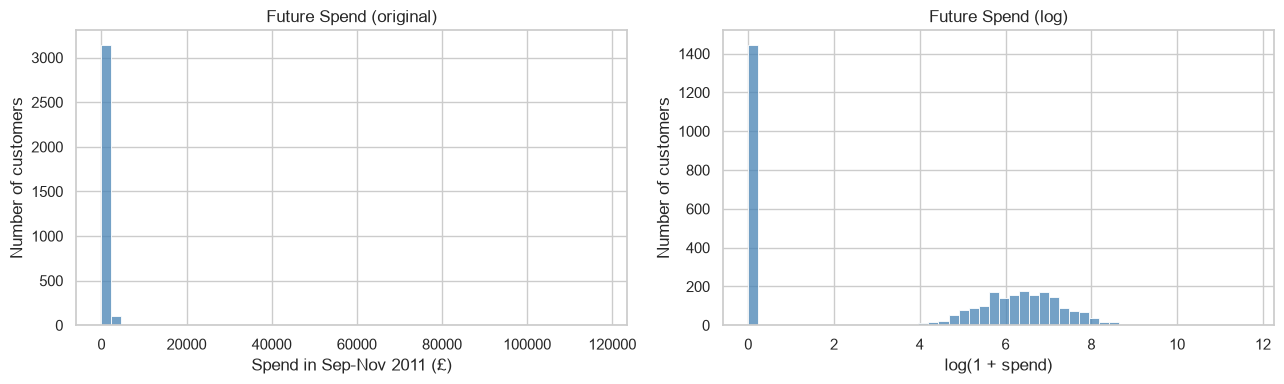

In [6]:
# Target distribution
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(customers["FutureSpend"], bins=50, ax=axes[0], color="steelblue")
axes[0].set_title("Future Spend (original)")
axes[0].set_xlabel("Spend in Sep-Nov 2011 (£)")
axes[0].set_ylabel("Number of customers")
sns.histplot(customers["LogFutureSpend"], bins=50, ax=axes[1], color="steelblue")
axes[1].set_title("Future Spend (log)")
axes[1].set_xlabel("log(1 + spend)")
axes[1].set_ylabel("Number of customers")
plt.tight_layout()
plt.show()

The original target is almost all near 0 with a few very large values. The log target is easier to model, but it has two groups: a big spike at 0 (customers who did not come back) and a bell shape for customers who did. This will make the problem harder for regression.

## Step 4: Feature Engineering

I created new features that I think can help predict future spending:

- RecentSpend and RecentOrders: spending and orders in the last 3 months of the past period (June to August). Recent behavior may matter more than old behavior.
- ActiveMonths: number of different months the customer bought in. This shows how regular the customer is.
- OrdersPerMonth: orders divided by how long the customer has been buying.
- AvgOrderValue: average money per order.
- TotalQuantity: total units bought.
- CancelRate: share of the customer's order lines that were cancelled.
- Log versions of the skewed features (Frequency, Monetary, Products, AvgOrderValue, TotalQuantity, RecentSpend).

In [7]:
# Feature engineering

# Recent activity (last 3 months of the past period)
recent = past[past["InvoiceDate"] >= pd.Timestamp("2011-06-01")]
customers["RecentSpend"] = recent.groupby("CustomerID")["LineTotal"].sum().reindex(customers.index).fillna(0)
customers["RecentOrders"] = recent.groupby("CustomerID")["InvoiceNo"].nunique().reindex(customers.index).fillna(0)

# How regular the customer is
customers["ActiveMonths"] = past.groupby("CustomerID")["InvoiceDate"].apply(
    lambda d: d.dt.to_period("M").nunique())
customers["OrdersPerMonth"] = customers["Frequency"] / (customers["TenureDays"] / 30 + 1)

# Order size
customers["AvgOrderValue"] = customers["Monetary"] / customers["Frequency"]
customers["TotalQuantity"] = past.groupby("CustomerID")["Quantity"].sum()

# Cancel rate
lines = past.groupby("CustomerID").size()
cancel_lines = past_cancels.groupby("CustomerID").size().reindex(customers.index).fillna(0)
customers["CancelRate"] = cancel_lines / (lines + cancel_lines)

# Log versions of skewed features
for col in ["Frequency", "Monetary", "Products", "AvgOrderValue", "TotalQuantity", "RecentSpend"]:
    customers["Log" + col] = np.log1p(customers[col])

customers[["RecentSpend", "RecentOrders", "ActiveMonths", "OrdersPerMonth",
           "AvgOrderValue", "TotalQuantity", "CancelRate"]].describe().T

,count,mean,std,min,25%,50%,75%,max
RecentSpend,"3,313.000",554.889,"2,486.442",0.000,0.000,150.400,494.170,"65,895.120"
RecentOrders,"3,313.000",1.200,2.109,0.000,0.000,1.000,2.000,44.000
ActiveMonths,"3,313.000",2.453,1.944,1.000,1.000,2.000,3.000,9.000
OrdersPerMonth,"3,313.000",0.486,0.568,0.099,0.202,0.349,0.592,12.475
AvgOrderValue,"3,313.000",369.876,482.176,2.900,167.115,279.087,409.197,"12,425.450"
TotalQuantity,"3,313.000",898.068,"3,499.148",1.000,128.000,305.000,766.000,"126,693.000"
CancelRate,"3,313.000",0.024,0.064,0.000,0.000,0.000,0.019,0.833


In [8]:
# Skewness before and after log
check = ["Frequency", "Monetary", "Products", "AvgOrderValue", "TotalQuantity", "RecentSpend"]
skew_table = pd.DataFrame({
    "Original": customers[check].skew(),
    "Log": customers[["Log" + c for c in check]].skew().values,
})
skew_table

,Original,Log
Frequency,9.097,1.394
Monetary,17.573,0.372
Products,6.127,-0.209
AvgOrderValue,10.715,-0.010
TotalQuantity,19.792,0.027
RecentSpend,17.524,-0.136


The log transform fixes the skew. For example, Monetary goes from a skewness of 17.6 to 0.4. Linear models work better when the features are not this skewed.

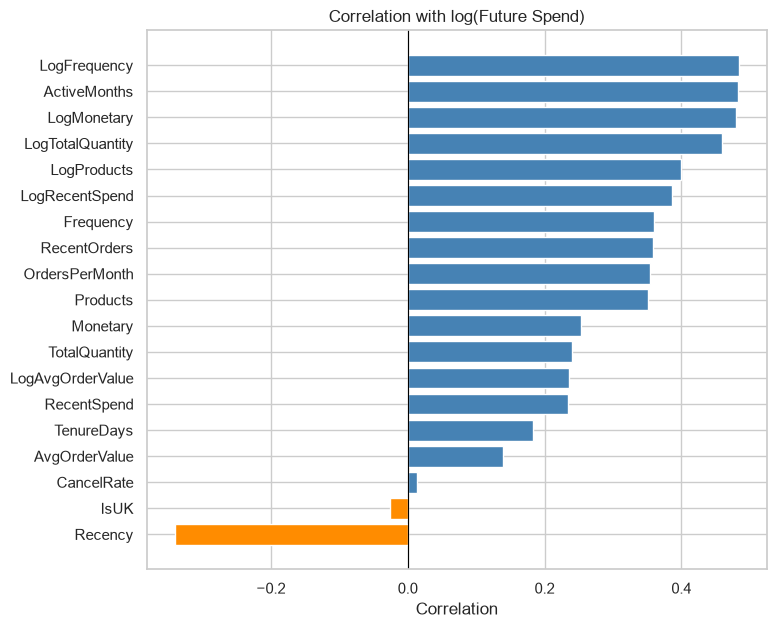

In [9]:
# Correlation of each feature with the target
features_all = ["Recency", "Frequency", "Monetary", "Products", "TenureDays", "IsUK",
                "RecentSpend", "RecentOrders", "ActiveMonths", "OrdersPerMonth", "AvgOrderValue",
                "TotalQuantity", "CancelRate", "LogFrequency", "LogMonetary", "LogProducts",
                "LogAvgOrderValue", "LogTotalQuantity", "LogRecentSpend"]
target_corr = customers[features_all].corrwith(customers["LogFutureSpend"]).sort_values()

plt.figure(figsize=(8, 7))
colors = ["darkorange" if v < 0 else "steelblue" for v in target_corr.values]
plt.barh(target_corr.index, target_corr.values, color=colors)
plt.axvline(0, color="black", linewidth=0.8)
plt.title("Correlation with log(Future Spend)")
plt.xlabel("Correlation")
plt.show()

- The log features have a stronger relationship with the target than the original ones. For example, LogMonetary has a correlation of about 0.48, but Monetary is only about 0.25.
- ActiveMonths, one of my new features, is one of the strongest features.
- Recency is the only feature with a clear negative relationship: customers who have not ordered for a long time spend less in the future.
- IsUK and CancelRate are close to 0, so they probably will not help much.

In [10]:
# Two feature sets
raw_features = ["Recency", "Frequency", "Monetary", "Products", "TenureDays", "IsUK"]

engineered_features = ["Recency", "LogFrequency", "LogMonetary", "LogProducts", "TenureDays", "IsUK",
                       "LogRecentSpend", "RecentOrders", "ActiveMonths", "OrdersPerMonth",
                       "LogAvgOrderValue", "LogTotalQuantity", "CancelRate"]

y = customers["LogFutureSpend"]
print("Raw features:", len(raw_features))
print("Engineered features:", len(engineered_features))

Raw features: 6
Engineered features: 13


To see if feature engineering helps, I compare two feature sets:

- Raw features (6): the basic features with no changes.
- Engineered features (13): log features plus the new features.

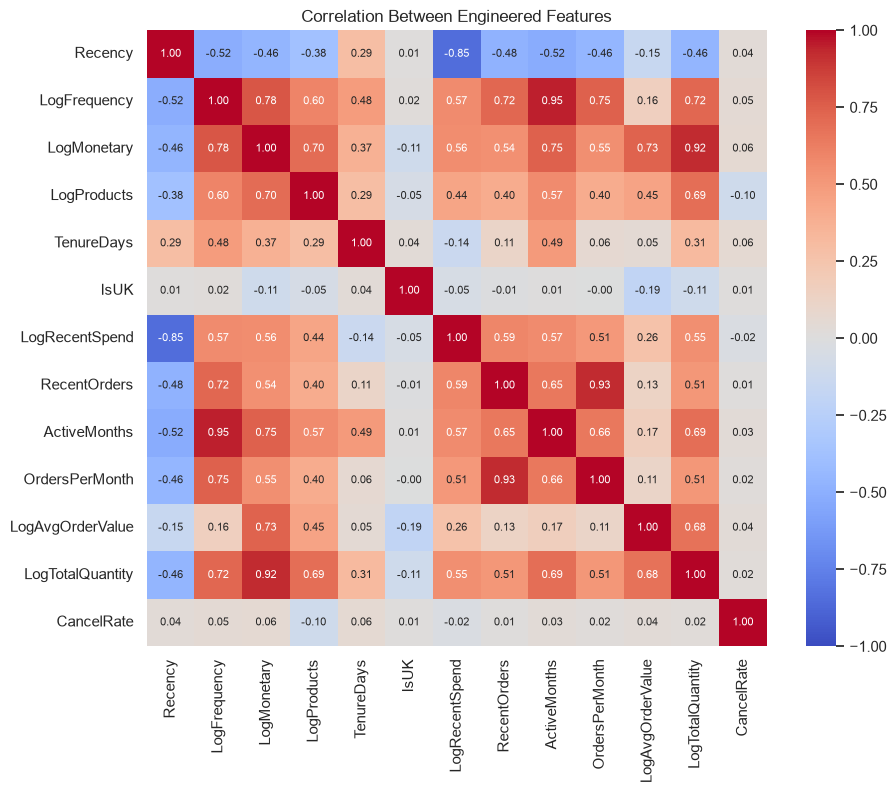

In [11]:
# Correlation between engineered features
plt.figure(figsize=(10, 8))
sns.heatmap(customers[engineered_features].corr(), annot=True, fmt=".2f", cmap="coolwarm",
            vmin=-1, vmax=1, annot_kws={"size": 8})
plt.title("Correlation Between Engineered Features")
plt.show()

Many engineered features are strongly related to each other (for example LogFrequency, ActiveMonths and LogMonetary). This is multicollinearity. It can make Linear Regression coefficients unstable, which is a good reason to also try Ridge and Lasso.

## Step 5: Train/Test Split

I keep 20% of the customers as a test set. The models never see these customers during training or cross-validation.

In [12]:
# Train/test split (80/20)
train_idx, test_idx = train_test_split(customers.index, test_size=0.2, random_state=42)
y_train, y_test = y.loc[train_idx], y.loc[test_idx]

print("Train customers:", len(train_idx))
print("Test customers:", len(test_idx))

Train customers: 2650
Test customers: 663


## Step 6: Choosing Alpha for Ridge and Lasso

Ridge and Lasso have a setting called alpha that controls how much the coefficients are shrunk. I tried many alpha values and used 5-fold cross-validation on the training set to pick the best one.

Best Ridge alpha: 300
Best Lasso alpha: 0.03


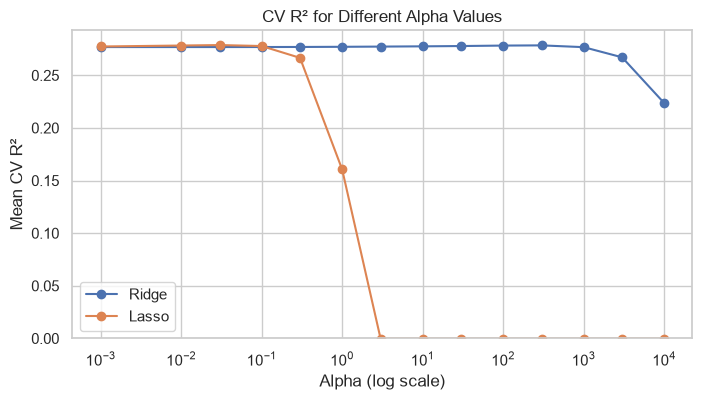

In [13]:
# Choose alpha for Ridge and Lasso with 5-fold CV
kfold = KFold(n_splits=5, shuffle=True, random_state=42)
X_train = customers.loc[train_idx, engineered_features]
alphas = [0.001, 0.01, 0.03, 0.1, 0.3, 1, 3, 10, 30, 100, 300, 1000, 3000, 10000]

ridge_scores, lasso_scores = [], []
for a in alphas:
    ridge = make_pipeline(StandardScaler(), Ridge(alpha=a))
    lasso = make_pipeline(StandardScaler(), Lasso(alpha=a, max_iter=10000))
    ridge_scores.append(cross_validate(ridge, X_train, y_train, cv=kfold, scoring="r2")["test_score"].mean())
    lasso_scores.append(cross_validate(lasso, X_train, y_train, cv=kfold, scoring="r2")["test_score"].mean())

best_ridge_alpha = alphas[int(np.argmax(ridge_scores))]
best_lasso_alpha = alphas[int(np.argmax(lasso_scores))]
print("Best Ridge alpha:", best_ridge_alpha)
print("Best Lasso alpha:", best_lasso_alpha)

plt.figure(figsize=(8, 4))
plt.plot(alphas, ridge_scores, marker="o", label="Ridge")
plt.plot(alphas, lasso_scores, marker="o", label="Lasso")
plt.xscale("log")
plt.title("CV R² for Different Alpha Values")
plt.xlabel("Alpha (log scale)")
plt.ylabel("Mean CV R²")
plt.ylim(0, None)
plt.legend()
plt.show()

- Ridge: the score barely changes with alpha. The best value is 300.
- Lasso: the best value is 0.03. When alpha is 1 or higher, Lasso removes almost all features and the score drops to 0.

I scale the features with StandardScaler before Ridge and Lasso, because alpha treats all coefficients the same, so the features need to be on the same scale.

## Step 7: Models

I compare 6 models:

- Baseline: always predicts the average. Any useful model must beat this.
- Linear Regression with raw features
- Linear Regression with engineered features (multiple regression)
- Ridge Regression with engineered features
- Lasso Regression with engineered features
- Random Forest with engineered features (a non-linear model, to see if it can do better than the linear ones)

In [14]:
# Models to compare: (name, feature set, model)
models = [
    ("Baseline (mean)", raw_features, DummyRegressor(strategy="mean")),
    ("Linear (raw)", raw_features, make_pipeline(StandardScaler(), LinearRegression())),
    ("Linear (engineered)", engineered_features, make_pipeline(StandardScaler(), LinearRegression())),
    ("Ridge", engineered_features, make_pipeline(StandardScaler(), Ridge(alpha=best_ridge_alpha))),
    ("Lasso", engineered_features, make_pipeline(StandardScaler(), Lasso(alpha=best_lasso_alpha, max_iter=10000))),
    ("Random Forest", engineered_features,
     RandomForestRegressor(n_estimators=300, min_samples_leaf=10, random_state=42, n_jobs=-1)),
]

## Step 8: Cross-Validation

I use 5-fold cross-validation on the training set. The training data is split into 5 parts, and each model is trained 5 times, each time tested on a different part. This shows how well the model works on data it has not seen.

In [15]:
# 5-fold cross-validation on the training set
cv_rows = []
cv_r2_folds = {}
for name, feats, model in models:
    scores = cross_validate(model, customers.loc[train_idx, feats], y_train, cv=kfold,
                            scoring=["r2", "neg_root_mean_squared_error"])
    cv_r2_folds[name] = scores["test_r2"]
    cv_rows.append({"Model": name,
                    "CV R² (mean)": scores["test_r2"].mean(),
                    "CV R² (std)": scores["test_r2"].std(),
                    "CV RMSE (mean)": -scores["test_neg_root_mean_squared_error"].mean()})

cv_results = pd.DataFrame(cv_rows).set_index("Model")
cv_results

,CV R² (mean),CV R² (std),CV RMSE (mean)
Model,,,
Baseline (mean),-0.000,0.000,3.273
Linear (raw),0.233,0.029,2.866
Linear (engineered),0.277,0.025,2.783
Ridge,0.278,0.024,2.780
Lasso,0.279,0.025,2.779
Random Forest,0.266,0.025,2.803


- All models beat the baseline.
- Feature engineering helps: Linear Regression goes from R² 0.233 (raw) to 0.277 (engineered).
- Linear, Ridge and Lasso with engineered features are almost the same (about 0.28).
- Random Forest is a little lower (0.266).
- The standard deviation across folds is small (about 0.025), so the results are stable and not just luck.

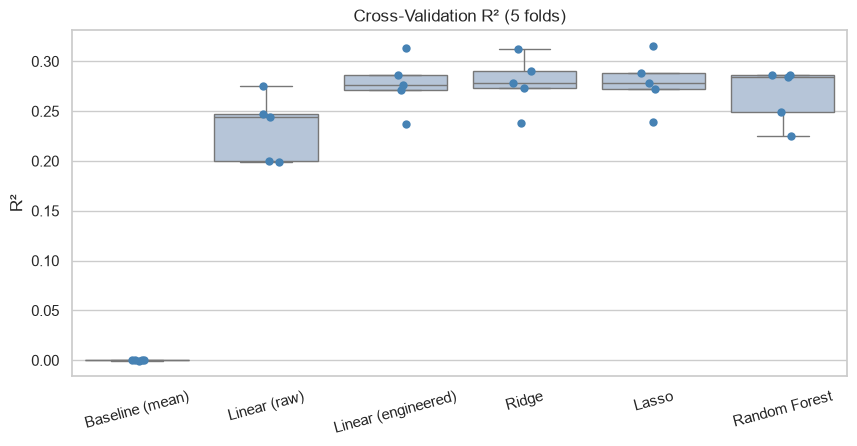

In [16]:
# CV R² for each fold
cv_long = pd.DataFrame(cv_r2_folds).melt(var_name="Model", value_name="R²")

plt.figure(figsize=(10, 4.5))
sns.boxplot(data=cv_long, x="Model", y="R²", color="lightsteelblue", showfliers=False)
sns.stripplot(data=cv_long, x="Model", y="R²", color="steelblue", size=6)
plt.title("Cross-Validation R² (5 folds)")
plt.xlabel("")
plt.xticks(rotation=15)
plt.show()

The box plot shows the R² for each of the 5 folds. The boxes for the engineered models are clearly higher than Linear (raw), so the improvement from feature engineering is not just luck.

## Step 9: Test Set Results

Now I train each model on the whole training set and test it on the 20% test set.

In [17]:
# Train on the full training set and evaluate on the test set
test_rows = []
predictions = {}
for name, feats, model in models:
    model.fit(customers.loc[train_idx, feats], y_train)
    pred = model.predict(customers.loc[test_idx, feats])
    predictions[name] = pred
    mse = mean_squared_error(y_test, pred)
    test_rows.append({"Model": name,
                      "R²": r2_score(y_test, pred),
                      "MSE": mse,
                      "RMSE": np.sqrt(mse),
                      "MAE": mean_absolute_error(y_test, pred)})

test_results = pd.DataFrame(test_rows).set_index("Model")
test_results

,R²,MSE,RMSE,MAE
Model,,,,
Baseline (mean),-0.000,10.891,3.300,3.164
Linear (raw),0.206,8.647,2.941,2.617
Linear (engineered),0.263,8.022,2.832,2.504
Ridge,0.263,8.028,2.833,2.513
Lasso,0.266,7.995,2.827,2.514
Random Forest,0.258,8.083,2.843,2.467


The test results agree with cross-validation:

- Lasso is the best model, with R² = 0.266 and RMSE = 2.827.
- Linear (engineered) and Ridge are almost the same (R² = 0.263).
- Random Forest has R² = 0.258, but the lowest MAE (2.467).
- Linear (raw) is clearly worse (R² = 0.206), and the baseline has R² = 0.

The differences between the top 4 models are very small. Lasso is the best choice because it has the best R² and RMSE, and it is also simpler, because it removes some features.

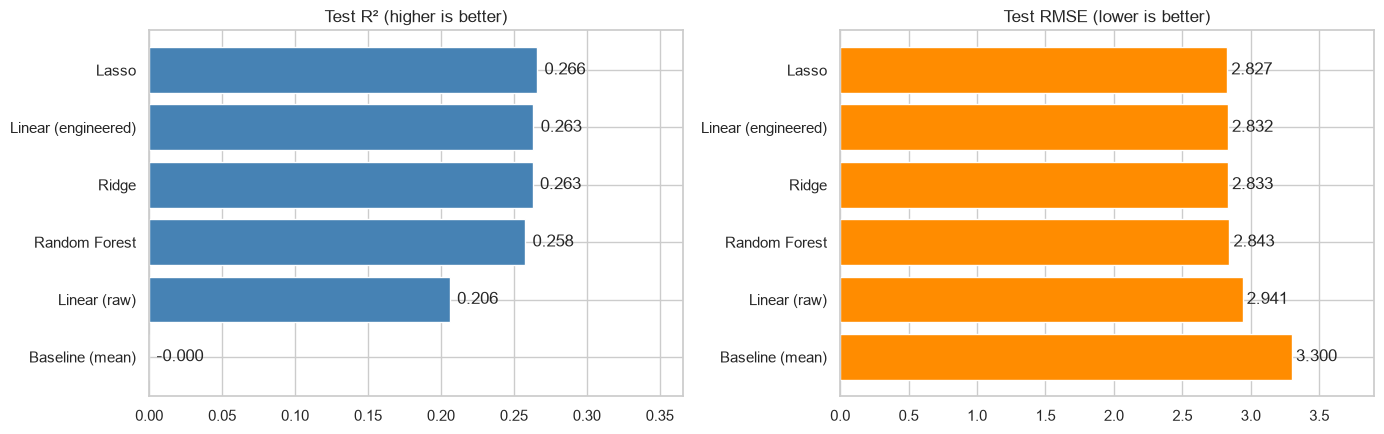

In [18]:
# Compare models on the test set
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
order = test_results.sort_values("R²").index

axes[0].barh(order, test_results.loc[order, "R²"], color="steelblue")
for i, v in enumerate(test_results.loc[order, "R²"]):
    axes[0].text(v + 0.005, i, f"{v:.3f}", va="center")
axes[0].set_title("Test R² (higher is better)")
axes[0].set_xlim(0, test_results["R²"].max() + 0.1)

axes[1].barh(order, test_results.loc[order, "RMSE"], color="darkorange")
for i, v in enumerate(test_results.loc[order, "RMSE"]):
    axes[1].text(v + 0.03, i, f"{v:.3f}", va="center")
axes[1].set_title("Test RMSE (lower is better)")
axes[1].set_xlim(0, test_results["RMSE"].max() + 0.6)
plt.tight_layout()
plt.show()

Best model: Lasso


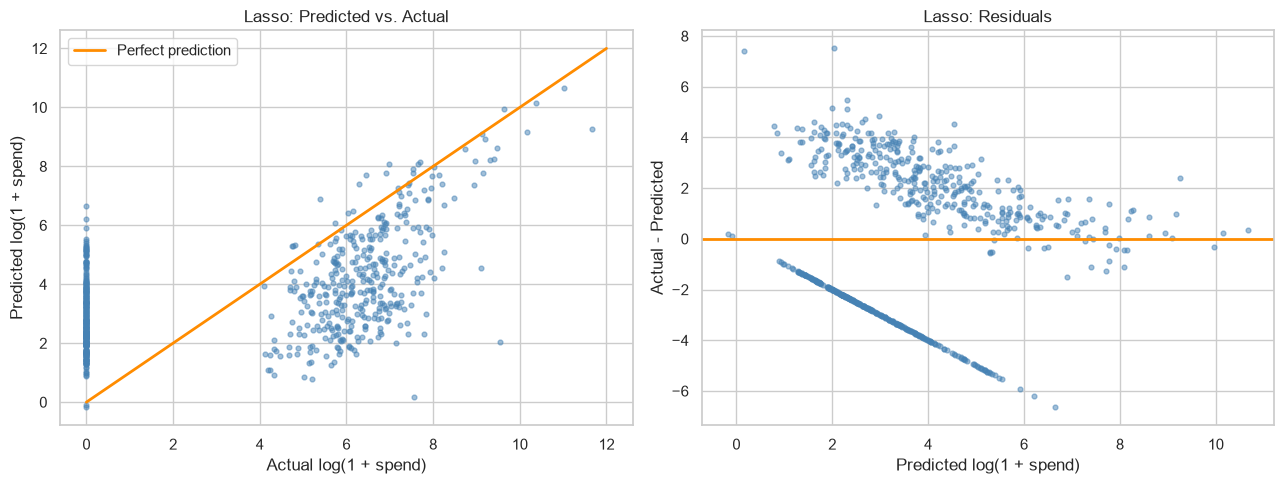

In [19]:
# Predicted vs. actual for the best model
best_name = test_results["R²"].idxmax()
best_pred = predictions[best_name]
print("Best model:", best_name)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].scatter(y_test, best_pred, s=12, alpha=0.5, color="steelblue")
axes[0].plot([0, 12], [0, 12], color="darkorange", linewidth=2, label="Perfect prediction")
axes[0].set_title(f"{best_name}: Predicted vs. Actual")
axes[0].set_xlabel("Actual log(1 + spend)")
axes[0].set_ylabel("Predicted log(1 + spend)")
axes[0].legend()

residuals = y_test - best_pred
axes[1].scatter(best_pred, residuals, s=12, alpha=0.5, color="steelblue")
axes[1].axhline(0, color="darkorange", linewidth=2)
axes[1].set_title(f"{best_name}: Residuals")
axes[1].set_xlabel("Predicted log(1 + spend)")
axes[1].set_ylabel("Actual - Predicted")
plt.tight_layout()
plt.show()

The left chart shows two groups:

- Customers who came back (actual above 4): the predictions follow the orange line, but they are usually too low.
- Customers who did not come back (actual = 0): the model still predicts 1 to 6 for many of them, because it cannot tell who will stop buying.

The residual chart shows the same thing as two bands. The straight line at the bottom is the customers with 0 spend. This is the main reason R² is not higher.

In [20]:
# Error for customers who came back vs. did not
came_back = customers.loc[test_idx, "FutureSpend"] > 0
for label, mask in [("Came back", came_back), ("Did not come back", ~came_back)]:
    err = np.sqrt(mean_squared_error(y_test[mask], best_pred[mask]))
    print(f"{label}: {mask.sum()} customers, RMSE = {err:.3f}")

Came back: 371 customers, RMSE = 2.608
Did not come back: 292 customers, RMSE = 3.084


The error is larger for customers who did not come back. The model is better at predicting how much returning customers spend than at predicting who will not come back.

In [21]:
# Extra test: only customers who came back
back_train = [c for c in train_idx if customers.loc[c, "FutureSpend"] > 0]
X_back = customers.loc[back_train, engineered_features]
y_back = customers.loc[back_train, "LogFutureSpend"]

for name, model in [("Linear", make_pipeline(StandardScaler(), LinearRegression())),
                    ("Lasso", make_pipeline(StandardScaler(), Lasso(alpha=best_lasso_alpha, max_iter=10000)))]:
    r2 = cross_validate(model, X_back, y_back, cv=kfold, scoring="r2")["test_score"]
    print(f"{name} on customers who came back: CV R² = {r2.mean():.3f}")
print("Customers used:", len(back_train))

Linear on customers who came back: CV R² = 0.443
Lasso on customers who came back: CV R² = 0.434
Customers used: 1495


To check this, I trained the models only on customers who came back. The CV R² goes up from about 0.28 to about 0.44. This shows that a big part of the problem is deciding whether a customer will come back at all. That is a classification problem, which I will work on in Deliverable 3.

## Step 10: Which Features Matter?

In [22]:
# Coefficients (scaled features) and Random Forest importance
ridge_model = models[3][2].named_steps["ridge"]
lasso_model = models[4][2].named_steps["lasso"]
rf_model = models[5][2]

coef = pd.DataFrame({
    "Linear": models[2][2].named_steps["linearregression"].coef_,
    "Ridge": ridge_model.coef_,
    "Lasso": lasso_model.coef_,
    "RF importance": rf_model.feature_importances_,
}, index=engineered_features).sort_values("RF importance", ascending=False)
print("Features removed by Lasso (coefficient = 0):", list(coef.index[coef["Lasso"] == 0]))
coef

Features removed by Lasso (coefficient = 0):

 ['LogAvgOrderValue', 'OrdersPerMonth', 'TenureDays', 'RecentOrders']


,Linear,Ridge,Lasso,RF importance
LogMonetary,0.613,0.259,0.365,0.238
ActiveMonths,0.616,0.428,0.598,0.213
LogTotalQuantity,0.197,0.219,0.185,0.131
LogProducts,0.291,0.271,0.272,0.078
LogAvgOrderValue,-0.159,0.060,0.000,0.067
LogRecentSpend,0.276,0.242,0.269,0.064
Recency,-0.076,-0.178,-0.061,0.059
OrdersPerMonth,-0.017,0.029,0.000,0.057
TenureDays,0.009,0.107,0.000,0.048
LogFrequency,0.050,0.307,0.244,0.025


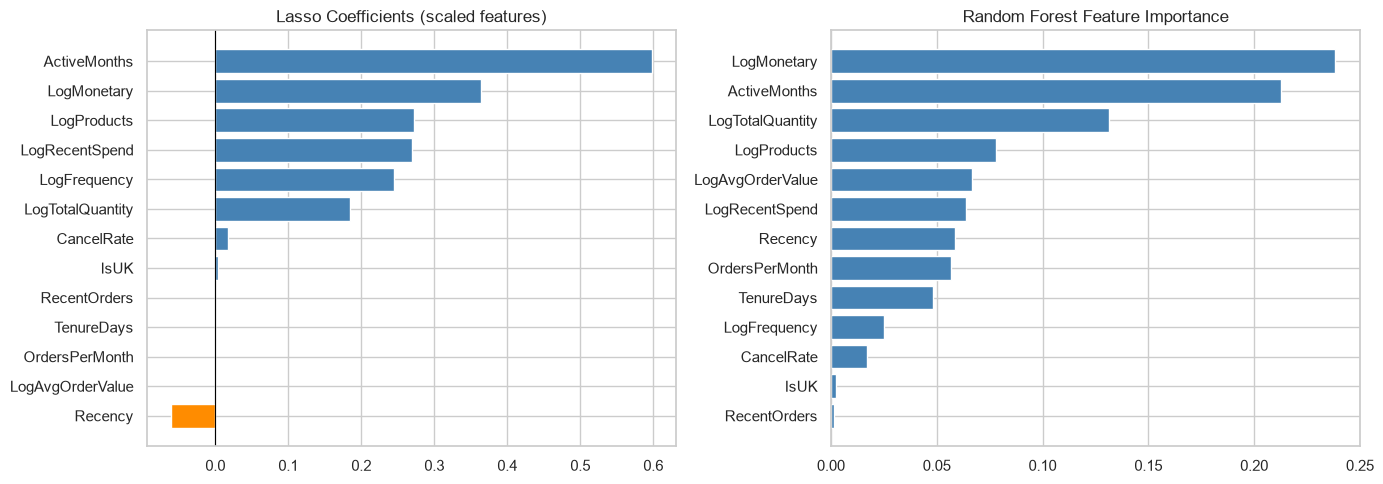

In [23]:
# Plot Lasso coefficients and Random Forest importance
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
lasso_sorted = coef["Lasso"].sort_values()
axes[0].barh(lasso_sorted.index, lasso_sorted.values,
             color=["darkorange" if v < 0 else "steelblue" for v in lasso_sorted.values])
axes[0].axvline(0, color="black", linewidth=0.8)
axes[0].set_title("Lasso Coefficients (scaled features)")

rf_sorted = coef["RF importance"].sort_values()
axes[1].barh(rf_sorted.index, rf_sorted.values, color="steelblue")
axes[1].set_title("Random Forest Feature Importance")
plt.tight_layout()
plt.show()

- ActiveMonths and LogMonetary are the most important features in both Lasso and Random Forest. Customers who buy in many different months and spend a lot keep spending.
- LogProducts, LogRecentSpend, LogTotalQuantity and LogFrequency also help.
- Recency has a negative coefficient: the longer since the last order, the lower the future spending.
- Lasso set 4 features to 0 (LogAvgOrderValue, OrdersPerMonth, TenureDays, RecentOrders). These overlap with other features, so they do not add new information.
- The Linear Regression coefficients are different from Ridge and Lasso (for example LogFrequency is 0.05 in Linear but 0.31 in Ridge). This is because of multicollinearity. Ridge and Lasso give more stable coefficients.

In [24]:
# Error in pounds for the best model (customers who came back)
actual_pounds = customers.loc[test_idx, "FutureSpend"]
pred_pounds = np.expm1(best_pred)
mask = actual_pounds > 0
print(f"Median actual spend: £{actual_pounds[mask].median():,.0f}")
print(f"Median absolute error: £{np.median(np.abs(actual_pounds[mask] - pred_pounds[mask])):,.0f}")

Median actual spend: £575
Median absolute error: £445


In pounds, for customers who came back, the typical (median) error is £445, while the typical spend is £575. So the predictions are useful for ranking customers (big vs. small spenders), but not exact enough for precise sales forecasts.

## Step 11: Summary of Results

In [25]:
# Final summary table
summary = cv_results[["CV R² (mean)", "CV R² (std)", "CV RMSE (mean)"]].join(test_results[["R²", "RMSE", "MAE"]])
summary.columns = ["CV R²", "CV R² std", "CV RMSE", "Test R²", "Test RMSE", "Test MAE"]
summary.sort_values("Test R²", ascending=False)

,CV R²,CV R² std,CV RMSE,Test R²,Test RMSE,Test MAE
Model,,,,,,
Lasso,0.279,0.025,2.779,0.266,2.827,2.514
Linear (engineered),0.277,0.025,2.783,0.263,2.832,2.504
Ridge,0.278,0.024,2.780,0.263,2.833,2.513
Random Forest,0.266,0.025,2.803,0.258,2.843,2.467
Linear (raw),0.233,0.029,2.866,0.206,2.941,2.617
Baseline (mean),-0.000,0.000,3.273,-0.000,3.300,3.164


## Step 12: Conclusion and Insights

Best model: Lasso Regression with engineered features. It had the best test R² (0.266) and RMSE (2.827), and a CV R² of 0.279. Ridge and Linear Regression with the same features were almost as good. Random Forest did not do better than the linear models, so a simple linear model is enough for this problem.

What I learned:

- Feature engineering made the biggest difference. Using log features and new features (like ActiveMonths and RecentSpend) raised R² from 0.206 to 0.266 on the test set. Changing the model type made much less difference.
- The best predictors are how regular the customer is (ActiveMonths), how much they spent (LogMonetary), and how many products they buy. Recent customers spend more.
- The features have multicollinearity. Ridge and Lasso handled this better and gave more stable coefficients. Lasso also removed 4 features that did not add information.
- Cross-validation and the test set gave similar results with small differences between folds, so the models generalize well to new customers.
- The R² is moderate (about 0.27) because 44% of customers did not come back at all. When I only used customers who came back, R² went up to about 0.44.

